# 서울 공공자전거 데이터 분석 실습

## 서울 공공자전거 대여 데이터

서울시 공공자전거 운영 담당자가 이렇게 말했습니다.

> "자전거가 언제, 어떤 때 많이 쓰이는지 알고 싶습니다."

이 말은 아직 **모호한 문제**입니다. 데이터를 직접 다루며 이 문제를 **분석할 수 있는 질문으로 바꾸고, 질문에 답하는 방법**을 익힙니다.

- **데이터** 서울 공공자전거의 1년(365일) × 24시간 대여 기록, 8,760행 14열
- **출처** UCI Machine Learning Repository, Seoul Bike Sharing Demand (https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

### 쓸 수 있는 도구

| 하고 싶은 일 | 도구 |
|:---|:---|
| 데이터 미리보기 | `head()` `tail()` `sample()` |
| 데이터 구조 확인 | `shape` `columns` `dtypes` `info()` |
| 변수 선택, 필터링 | `df[["열"]]` `df[조건]` `&` `\|` `unique()` |
| 열 추가 | `df["새 열"] = 계산` |
| 정렬 | `sort_values()` |
| 결측값, 중복값 확인 | `isna()` `duplicated()` |
| 빈도 계산 | `value_counts()` `len()` |
| 기술통계 | `describe()` `mean()` `median()` |
| 그룹별 집계 | `groupby()` `agg()` `idxmax()` `unstack()` |
| 상관계수 | `corr()` |
| 표 만들기 | `pd.DataFrame()` `round()` |
| 그래프 | `plot(kind="bar")` `plot(kind="hist")` `boxplot()` `plot(kind="line")` `plot(kind="scatter")` `set_ylim()` |

### 교수용 지도 포인트 (학생용 노트북에는 표시하지 않음)

- **1.14** 대여량 0인 행이 모두 비운영일임을 학생이 스스로 발견하는 것이 핵심입니다. 먼저 알려 주지 마세요.
- **1.16** 기준을 넘는 큰 값이 오류가 아님(여름 저녁의 실제 수요)을 알게 하는 것이 핵심입니다. 이론의 카페 45분과 대비됩니다.
- **3** 그래프(막대, 히스토그램, 상자그림, 선, 산점도, 묶은 막대, 해석, 축 시작점)을 같은 데이터로 확인합니다. 그래프 도우미 함수는 제공되는 셀을 실행하게 합니다.
- **2.5** 학생마다 도출하는 질문이 다를 수 있습니다. 어떤 질문이든 다섯 요소와 네 가지 점검(특히 "답이 이미 나와 있지 않은가")을 통과하는지로 확인합니다.

## 데이터 불러오기

아래 두 셀은 **이미 작성되어 있습니다.** 실행만 하세요. 이 파일은 온도 기호(°) 때문에 `encoding="latin1"`로 읽어야 글자가 깨지지 않습니다.

In [1]:
from pathlib import Path
import pandas as pd

URL = "https://raw.githubusercontent.com/phyzikyh/computing/main/%EA%B0%95%EC%9D%98%EA%B5%90%EC%9E%AC/data/SeoulBikeData.csv"


def find_file(name):
    starts = [Path.cwd()]
    notebook = globals().get("__vsc_ipynb_file__")      # VS Code에서 노트북이 있는 위치
    if notebook:
        starts.insert(0, Path(notebook).parent)
    for start in starts:
        for folder in [start, *start.parents][:4]:
            for sub in ["", "data", "강의교재/data"]:
                path = folder / sub / name
                if path.exists():
                    return path
    return None


data_path = find_file("SeoulBikeData.csv")
source = data_path if data_path else URL          # 컴퓨터에 없으면 인터넷에서 내려받습니다.
bike = pd.read_csv(source, encoding="latin1")
print("불러온 곳:", source)

불러온 곳: c:\Users\user\Desktop\2026년_2학기 강의\1_computing\강의교재\data\SeoulBikeData.csv


In [ ]:
bike = bike.rename(columns={
    "Date": "date",
    "Rented Bike Count": "rented_count",
    "Hour": "hour",
    "Temperature(°C)": "temperature",
    "Humidity(%)": "humidity",
    "Wind speed (m/s)": "wind_speed",
    "Visibility (10m)": "visibility",
    "Dew point temperature(°C)": "dew_point",
    "Solar Radiation (MJ/m2)": "solar_radiation",
    "Rainfall(mm)": "rainfall",
    "Snowfall (cm)": "snowfall",
    "Seasons": "season",
    "Holiday": "holiday",
    "Functioning Day": "functioning_day",
})
print(bike.columns.tolist())

['date', 'rented_count', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point', 'solar_radiation', 'rainfall', 'snowfall', 'season', 'holiday', 'functioning_day']


# 1. EDA 절차 따라 하기

분석 질문이 하나 주어졌습니다. 이 질문에 답하는 과정을 이론과 같은 순서로 밟습니다.

> 서울 공공자전거의 시간대별 평균 대여량은 어떻게 다르며, 어느 시간대에 대여가 가장 많은가?

### 1.1 분석 질문에 필요한 변수 정의

데이터를 열기 전에 먼저 생각합니다. ① 이 질문에 **필요한 변수(열)** ② **필요 없는 변수** ③ **집계 방법**을 쓰세요. 그리고 ④ 분석을 시작하기 전에 데이터가 이 질문에 답할 수 있는지 **점검해야 할 항목 네 가지**를 쓰세요.

**확인값** 필요한 열은 두 개입니다. 네 가지는 이론의 점검표(열 존재, 비어 있음, 값의 범위, 그룹별 건수)를 떠올리세요.

> ① **필요한 변수** `hour`(기준 변수), `rented_count`(측정 변수)
> ② **필요 없는 변수** `temperature`, `season`, `holiday` 등 나머지
> ③ **집계 방법** 평균
> ④ **점검 항목** 열이 있는가 / 비어 있는 값은 없는가 / 값이 올바른 범위인가 / 시간대마다 건수가 충분한가

### 1.2 변수의 종류 분류

`bike`의 열 14개를 **범주형**과 **연속형**으로 분류하세요. 숫자로 저장되어 있지만 범주처럼 다루는 열이 있다면 이유와 함께 쓰세요. 이 분석 질문(시간대별 평균 대여량)에서 `hour`와 `rented_count`는 각각 어느 쪽으로 다룹니까?

> **교수용 예시**
> - **범주형** `season`, `holiday`, `functioning_day`, `date`(날짜를 구분하는 값)
> - **연속형** `rented_count`, `temperature`, `humidity`, `wind_speed`, `visibility`, `dew_point`, `solar_radiation`, `rainfall`, `snowfall`
> - `hour`는 0~23의 숫자지만 시간대를 서로 비교하는 **기준**으로 쓰므로 범주처럼 다룹니다. 평균을 낼 대상은 연속형인 `rented_count`입니다.

In [3]:
print(bike.dtypes)

date                   str
rented_count         int64
hour                 int64
temperature        float64
humidity             int64
wind_speed         float64
visibility           int64
dew_point          float64
solar_radiation    float64
rainfall           float64
snowfall           float64
season                 str
holiday                str
functioning_day        str
dtype: object


### 1.3 데이터프레임 확인

`bike`에는 무엇이 저장되어 있습니까? 파일 이름입니까, 표입니까? 자료형을 코드로 확인하고, 이 데이터에서 **관측치(행) 하나**와 **변수(열) 하나**가 각각 무엇을 나타내는지 설명하세요.

**확인값** `pandas`의 `DataFrame`입니다.

**힌트** `type()`으로 자료형을 확인합니다.

> 관측치(행) 하나는 **날짜와 시간으로 정해지는 한 시간 동안의 대여 건수와 날씨 기록**이고, 변수(열) 하나는 그 기록의 **한 가지 속성**(대여량, 기온 등)입니다.

In [4]:
print(type(bike))

<class 'pandas.DataFrame'>


### 1.4 데이터 미리보기

데이터의 처음 5행, 마지막 3행, 무작위 표본 3행(`random_state=10`으로 고정)을 미리 보세요. 세 가지를 **모두** 확인하는 이유를 설명하세요.

**확인값** 마지막 행의 날짜는 `30/11/2018`, 시간은 `23`입니다.

> 처음과 끝만 보면 중간의 문제를 놓칠 수 있어 무작위 행도 함께 봅니다. 행이 날짜·시간 순서로 정렬되어 있다는 것도 알 수 있습니다.

In [5]:
display(bike.head())
display(bike.tail(3))
display(bike.sample(3, random_state=10))

,date,rented_count,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,season,holiday,functioning_day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


,date,rented_count,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,season,holiday,functioning_day
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes
8759,30/11/2018,584,23,1.9,43,1.3,1909,-9.3,0.0,0.0,0.0,Autumn,No Holiday,Yes


,date,rented_count,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,season,holiday,functioning_day
389,17/12/2017,31,5,-9.7,41,3.1,2000,-20.5,0.00,0.0,0.0,Winter,No Holiday,Yes
8461,18/11/2018,905,13,9.9,37,2.1,1900,-4.1,1.32,0.0,0.0,Autumn,No Holiday,Yes
3588,29/04/2018,1375,12,20.5,31,2.6,1299,2.7,2.79,0.0,0.0,Spring,No Holiday,Yes


### 1.5 데이터 크기와 변수 자료형

관측치(행)와 변수(열)의 수, 변수 이름, 변수별 자료형을 확인하세요. 수치형 변수 세 가지와 문자열(범주형) 변수 세 가지를 적으세요.

**확인값** 행과 열은 `(8760, 14)`입니다.

> 수치형 `rented_count`, `hour`, `temperature` / 문자열 `date`, `season`, `holiday`

In [6]:
print(bike.shape)
print(bike.columns.tolist())
print(bike.dtypes)

(8760, 14)
['date', 'rented_count', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point', 'solar_radiation', 'rainfall', 'snowfall', 'season', 'holiday', 'functioning_day']
date                   str
rented_count         int64
hour                 int64
temperature        float64
humidity             int64
wind_speed         float64
visibility           int64
dew_point          float64
solar_radiation    float64
rainfall           float64
snowfall           float64
season                 str
holiday                str
functioning_day        str
dtype: object


### 1.6 info()로 데이터 구조 확인

`info()`를 실행하고 `Non-Null Count`와 `Dtype`을 읽으세요. 비어 있는 값이 있는 열이 있습니까? `date`는 어떤 자료형이며, **이 질문에서** 날짜를 날짜형으로 바꿀 필요가 있습니까?

> 모든 열이 8760으로 같아 비어 있는 값이 없습니다. `date`는 문자열이지만 이 질문은 `hour`로 나누므로 날짜형으로 바꿀 필요가 없습니다.

In [7]:
bike.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             8760 non-null   str    
 1   rented_count     8760 non-null   int64  
 2   hour             8760 non-null   int64  
 3   temperature      8760 non-null   float64
 4   humidity         8760 non-null   int64  
 5   wind_speed       8760 non-null   float64
 6   visibility       8760 non-null   int64  
 7   dew_point        8760 non-null   float64
 8   solar_radiation  8760 non-null   float64
 9   rainfall         8760 non-null   float64
 10  snowfall         8760 non-null   float64
 11  season           8760 non-null   str    
 12  holiday          8760 non-null   str    
 13  functioning_day  8760 non-null   str    
dtypes: float64(6), int64(4), str(4)
memory usage: 1.2 MB


### 1.7 열 하나 꺼내기와 고유값

`bike`에서 열 하나(`season`)를 꺼내 **타입**을 확인하세요. 그다음 `season`, `holiday`, `functioning_day` 세 열이 각각 가진 **고유한 값**을 확인하세요. 계절은 몇 종류입니까?

> **확인** 열 하나를 꺼내면 Series입니다. `season`은 ['Winter', 'Spring', 'Summer', 'Autumn']의 4종류, `holiday`는 ['No Holiday', 'Holiday'], `functioning_day`는 ['Yes', 'No']입니다.

In [8]:
print(type(bike["season"]))
print(bike["season"].unique())
print(bike["holiday"].unique())
print(bike["functioning_day"].unique())

<class 'pandas.Series'>
<ArrowStringArray>
['Winter', 'Spring', 'Summer', 'Autumn']
Length: 4, dtype: str
<ArrowStringArray>
['No Holiday', 'Holiday']
Length: 2, dtype: str
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


### 1.8 변수 선택과 필터링

질문에 필요한 변수(열) 두 개만 선택해 새 이름으로 저장하고 앞부분을 확인하세요. 그다음 **18시 관측치**만 필터링해 몇 건인지 세세요.

**확인값** 18시 기록은 365건입니다. (1년이 365일이므로 하루에 한 건씩)

In [9]:
selected = bike[["hour", "rented_count"]]
display(selected.head())

evening = bike[bike["hour"] == 18]
print("18시 기록 수:", len(evening))

,hour,rented_count
0,0,254
1,1,204
2,2,173
3,3,107
4,4,78


18시 기록 수: 365


### 1.9 복합 조건 필터링

**18시이고 기온이 25도 이상인** 관측치가 몇 건인지 구하세요. 조건 두 개를 함께 쓸 때 코드에서 주의할 점을 한 줄로 쓰세요.

**확인값** 92건입니다.

> 각 조건을 괄호로 묶고 `&`로 연결합니다.

In [10]:
hot_evening = bike[
    (bike["hour"] == 18)
    & (bike["temperature"] >= 25)
]
print("18시이고 25도 이상인 기록 수:", len(hot_evening))

18시이고 25도 이상인 기록 수: 92


### 1.10 새로운 열 만들기

비가 온 시간인지를 나타내는 열 `is_rain`을 `bike`에 만드세요. `rainfall`(강수량, mm)이 0보다 크면 `True`, 아니면 `False`입니다. 새 열을 만든 뒤 `True`와 `False`가 각각 몇 건인지 세고, 비가 온 시간이 전체의 몇 %인지 구하세요. 이 열은 뒤에서 비 오는 시간과 비 안 오는 시간을 비교할 때 사용합니다.

**힌트** 조건식 `bike["rainfall"] > 0`의 결과(True/False)를 그대로 새 열에 저장합니다. 비율은 `True`의 개수 ÷ 전체 행 수 × 100입니다.

> **확인** 비가 온 시간은 528건으로 전체 8,760건의 6.0%입니다. 비교 조건을 열로 만들어 두면 뒤에서 그룹을 나눌 때 같은 조건을 다시 쓰지 않아도 됩니다.

In [11]:
bike["is_rain"] = bike["rainfall"] > 0

print(bike["is_rain"].value_counts())
print("비가 온 시간의 비율(%):", round(bike["is_rain"].mean() * 100, 1))

is_rain
False    8232
True      528
Name: count, dtype: int64
비가 온 시간의 비율(%): 6.0


### 1.11 정렬로 상위 관측치 확인

대여량이 **가장 큰** 관측치 5개를 날짜, 시간, 대여량, 계절과 함께 확인하세요. 어떤 공통점이 있습니까?

**확인값** 가장 큰 값은 3556입니다.

> 5개 모두 **여름(6월)의 18시**입니다. 큰 값이 임의의 오류가 아니라 특정 조건(계절과 시간)에 집중되어 있습니다.

In [12]:
bike.sort_values("rented_count", ascending=False)[["date", "hour", "rented_count", "season"]].head(5)

,date,hour,rented_count,season
4818,19/06/2018,18,3556,Summer
4866,21/06/2018,18,3418,Summer
4650,12/06/2018,18,3404,Summer
4842,20/06/2018,18,3384,Summer
4458,04/06/2018,18,3380,Summer


### 1.12 결측값 확인

변수별 결측값의 개수를 구하고, 데이터 전체의 합계도 구하세요.

**확인값** 합계는 0입니다.

> 모든 열이 0이고 전체 합계도 0입니다. **결측이 없다는 것도 확인한 결과**입니다.

In [13]:
print(bike.isna().sum())
print("전체:", bike.isna().sum().sum())

date               0
rented_count       0
hour               0
temperature        0
humidity           0
wind_speed         0
visibility         0
dew_point          0
solar_radiation    0
rainfall           0
snowfall           0
season             0
holiday            0
functioning_day    0
is_rain            0
dtype: int64
전체: 0


### 1.13 중복값 확인

중복된 행이 몇 개인지 구하고, 있다면 중복된 행을 **모두** 표시하는 방법으로 확인하세요.

**확인값** 0건입니다. 겹친 행을 보여 주는 코드는 빈 표를 돌려줍니다.

**힌트** `duplicated()`, 중복된 행을 모두 표시할 때는 `duplicated(keep=False)`

> 0건이며, 겹친 행을 보여 주는 코드(`keep=False`)도 빈 표를 돌려줍니다.

In [14]:
print("중복 행:", bike.duplicated().sum())
bike[bike.duplicated(keep=False)]

중복 행: 0


,date,rented_count,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,season,holiday,functioning_day,is_rain


### 1.14 비정상 값 탐색

결측값도 중복값도 없습니다. 그런데 이 데이터를 그대로 분석에 사용해도 될까요? 대여량이 가장 **작은** 관측치부터 확인하세요. 비정상적이거나 설명이 필요한 값이 있습니까? 있다면 **몇 건인지**, **어떤 공통점이 있는지**를 코드로 확인하세요.

**확인값** 대여량이 0인 행은 295건입니다. 공통점을 찾는 열은 하나입니다.

**힌트** `sort_values()`로 작은 값부터 보고, 대여량이 0인 행만 걸러 다른 변수와 함께 봅니다. 다른 열을 `value_counts()`로 세어 보면 단서가 나옵니다.

> 대여량이 0인 295행은 **모두 운영하지 않은 날**(`functioning_day`가 `No`)이고 13일에 걸쳐 있습니다. 시간대와 상관없이 하루 종일 0이므로 "빌릴 사람이 없었다"가 아니라 **운영을 하지 않아 0으로 기록된 것**입니다.

In [15]:
low = bike.sort_values("rented_count")
display(low[["date", "hour", "rented_count", "functioning_day"]].head(5))

zero_rows = bike[bike["rented_count"] == 0]
print("대여량이 0인 행:", len(zero_rows))
print(zero_rows["functioning_day"].value_counts())

,date,hour,rented_count,functioning_day
7340,02/10/2018,20,0,No
7019,19/09/2018,11,0,No
7020,19/09/2018,12,0,No
7021,19/09/2018,13,0,No
7022,19/09/2018,14,0,No


대여량이 0인 행: 295
functioning_day
No    295
Name: count, dtype: int64


### 1.15 데이터 전처리 방법 결정

이 관측치들을 어떻게 처리할지 정합니다. 다음 두 가지 방법으로 **평균 대여량을 계산해 비교**한 뒤, 전처리 방법을 결정하세요.

- **방법 A** 모든 관측치를 그대로 사용
- **방법 B** 문제가 되는 관측치를 제외하고 사용 (제외한 데이터를 `operating`이라는 이름으로 저장하세요)

**무엇을 제외했고 왜 그렇게 했는지** 전처리 기준을 글로 쓰세요. 이후 분석은 선택한 데이터로 합니다.

**확인값** 방법 A 704.6 / 방법 B 729.2 / 제외한 행 295

> 방법 B를 선택했습니다.
> - **제외한 관측치** `functioning_day`가 `No`인 295행
> - **제외한 이유** 운영하지 않은 날의 0건은 대여 수요가 아니어서, 포함하면 수요를 실제보다 낮게 계산하기 때문

In [16]:
all_mean = bike["rented_count"].mean()

operating = bike[bike["functioning_day"] == "Yes"]
op_mean = operating["rented_count"].mean()

print("방법 A 전체 평균:", round(all_mean, 1))
print("방법 B 운영일만 평균:", round(op_mean, 1))
print("제외한 행:", len(bike) - len(operating))

방법 A 전체 평균: 704.6
방법 B 운영일만 평균: 729.2
제외한 행: 295


### 1.16 이상값 탐지 기준

1.11에서 대여량이 매우 큰 관측치를 확인했습니다. 이 값들이 **이상값 후보**인지 IQR 기준으로 판정하세요. `operating`의 대여량으로 계산합니다.

- **위쪽 한계** Q3 + 1.5 × IQR (IQR = Q3 − Q1)

위쪽 한계값과, 한계를 **넘는 관측치의 수**를 구하세요. 초과한 관측치가 어느 시간대와 계절에 집중되어 있는지도 확인한 뒤, **이 관측치들을 제외해야 하는지** 판단하세요.

**확인값** 위쪽 한계 2389.0, 넘는 관측치 152건

**힌트** `describe()`의 `25%`(Q1)와 `75%`(Q3), 한계를 넘는 행은 조건 필터링과 `value_counts()`

> 위쪽 한계 2389.0건을 넘는 관측치는 152건입니다. 이 기록은 **18~19시 여름·봄·가을**에 몰려 있습니다. 오류가 아니라 **실제로 대여가 많은 시간대의 값**이므로 **제외하지 않습니다.** 이론의 카페 45분(다른 값과 동떨어진 한 건)과 달리, 이 값들은 이유를 설명할 수 있기 때문입니다.

In [17]:
r = operating["rented_count"]
d = r.describe()
iqr_limit = d["75%"] + 1.5 * (d["75%"] - d["25%"])

print("위쪽 한계:", iqr_limit)
print("한계를 넘는 관측치:", (r > iqr_limit).sum(), "건")

flagged = operating[r > iqr_limit]
print(flagged["hour"].value_counts().head(3))
print(flagged["season"].value_counts())

위쪽 한계: 2389.0
한계를 넘는 관측치: 152 건
hour
18    86
19    34
20    15
Name: count, dtype: int64
season
Summer    85
Autumn    35
Spring    32
Name: count, dtype: int64


### 1.17 기술통계 요약

`operating`의 대여량을 요약하세요.

1. 개수, 평균, 표준편차, 사분위수, 최댓값을 한 번에 확인하세요.
2. 평균과 중앙값을 비교하고, 차이가 말해 주는 것을 쓰세요.
3. 계절과 공휴일 여부의 **빈도와 비율(%)**을 구하세요. 비율이 한쪽으로 치우친 변수가 있다면, 그것이 그룹 비교에 어떤 영향을 줄지 생각해 보세요.

**확인값** 평균 729.2, 중앙값 542.0, 75% 1084, 최댓값 3556 / 공휴일 `No Holiday` 95.2%, `Holiday` 4.8%

**힌트** 비율(%)은 `value_counts()` ÷ 전체 행 수 × 100

> 평균(729.2)이 중앙값(542.0)보다 큽니다. 값의 75%가 1084건 이하인데 최댓값이 3556건이라, 대여가 많은 일부 기록이 평균을 끌어올렸습니다. 계절은 비슷한 비율이지만 공휴일은 4.8%(408건)뿐이어서, 공휴일 평균은 **건수가 적어 불안정**할 수 있습니다.

In [18]:
r = operating["rented_count"]
display(r.describe().round(1))
print("평균:", round(r.mean(), 1), "| 중앙값:", r.median())

for col in ["season", "holiday"]:
    print(operating[col].value_counts())
    print((operating[col].value_counts() / len(operating) * 100).round(1))
    print()

count    8465.0
mean      729.2
std       642.4
min         2.0
25%       214.0
50%       542.0
75%      1084.0
max      3556.0
Name: rented_count, dtype: float64

평균: 729.2 | 중앙값: 542.0
season
Summer    2208
Winter    2160
Spring    2160
Autumn    1937
Name: count, dtype: int64
season
Summer    26.1
Winter    25.5
Spring    25.5
Autumn    22.9
Name: count, dtype: float64

holiday
No Holiday    8057
Holiday        408
Name: count, dtype: int64
holiday
No Holiday    95.2
Holiday        4.8
Name: count, dtype: float64



### 1.18 그룹별 집계와 분석 질문 답하기

처음 질문에 답합니다.

1. 시간대별로 **관측치 수, 평균, 중앙값**을 집계하세요. 표본 크기가 충분한지 `count`로 확인하세요.
2. 평균이 가장 큰 시간대를 **코드로** 찾고, 상위 3개와 하위 3개 시간대를 확인하세요.
3. 1.15의 전처리 결정이 결론을 바꾸는지 확인하세요(민감도 확인). `operating`과 `bike`(전체)로 같은 집계를 해 **나란히** 놓고 비교하세요. 가장 많은 시간대가 달라집니까? 값은 얼마나 달라집니까?
4. 질문에 **한 문장**으로 답하세요.

**확인값** 많은 3곳 18시 1554.0, 19시 1235.8, 17시 1177.2 / 가장 적은 곳 4시 137.5 / 시간대마다 352~353건

**힌트** 3번은 두 집계의 평균 열을 `pd.DataFrame({"운영일만": …, "전체": …})`로 나란히 놓습니다.

> 가장 많은 시간대는 **18시(평균 1554.0건)**로 4시(평균 137.5건)의 약 11.3배입니다. 비운영일을 포함해도 가장 많은 시간대는 18시로 **같지만**, 평균은 1502.9건에서 1554.0건으로 달라집니다. 순위는 그대로여도 "얼마나 많은가"는 처리 방법에 따라 달라집니다.

In [19]:
hourly = (
    operating
    .groupby("hour")["rented_count"]
    .agg(["count", "mean", "median"])
    .round(1)
)
display(hourly)

best_hour = hourly["mean"].idxmax()
print("가장 많은 시간대:", best_hour, "시,", hourly.loc[best_hour, "mean"], "건")
print(hourly["mean"].sort_values(ascending=False).head(3))
print(hourly["mean"].sort_values().head(3))

hourly_all = bike.groupby("hour")["rented_count"].agg(["count", "mean"]).round(1)
compare = pd.DataFrame({"운영일만": hourly["mean"], "전체": hourly_all["mean"]})
compare["차이"] = (compare["운영일만"] - compare["전체"]).round(1)
compare.sort_values("차이", ascending=False).head(3)

,count,mean,median
hour,,,
0,352,561.5,531.5
1,352,441.9,411.5
2,352,312.8,277.0
3,352,210.8,183.5
4,352,137.5,123.5
5,352,144.2,136.5
6,352,298.2,245.0
7,353,626.6,443.0
8,353,1050.2,767.0


가장 많은 시간대: 18 시, 1554.0 건
hour
18    1554.0
19    1235.8
17    1177.2
Name: mean, dtype: float64
hour
4    137.5
5    144.2
3    210.8
Name: mean, dtype: float64


,운영일만,전체,차이
hour,,,
18,1554.0,1502.9,51.1
19,1235.8,1195.1,40.7
17,1177.2,1138.5,38.7


# 2. 탐색 결과로 분석 질문 만들기

1에서 익힌 필터링, 집계, 비율 계산을 그대로 쓰면서 한 단계 더 나아갑니다. 1에서는 분석 질문이 주어졌지만, 이번에는 탐색 결과에서 **질문을 직접 만들고** 그 질문에 답합니다. 계절과 공휴일 여부를 탐색하고(2.1~2.3), 설명되지 않은 의문을 정리한 뒤(2.4), 분석 질문으로 바꿔(2.5) 답하고(2.6), 처음의 모호한 요청에 종합해 답합니다(2.7).

데이터는 계속 `operating`을 씁니다.

### 2.1 계절별 집계

1.18에서 시간대별로 한 집계를 이번에는 `season`별로 하세요. 관측치 수, 평균, 중앙값을 구하고, 평균 대여량이 가장 큰 계절과 가장 작은 계절은 무엇이며, 몇 배 차이가 납니까?

> **관찰** 평균이 가장 큰 계절은 여름(1034.1건), 가장 작은 계절은 겨울(225.5건)로 약 4.6배 차이입니다. 계절에 따라 대여량의 수준이 크게 다릅니다.

In [20]:
operating.groupby("season")["rented_count"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
season,,,
Autumn,1937,924.1,856.0
Spring,2160,746.3,599.0
Summer,2208,1034.1,905.5
Winter,2160,225.5,203.0


### 2.2 공휴일 여부별 집계

`holiday`별로 같은 집계를 하세요. 1.17에서 확인한 것처럼 값이 한쪽으로 치우쳤을 수 있으므로 관측치 수도 함께 확인하세요. 어느 쪽 평균이 더 높습니까? 공휴일 기록은 몇 건입니까?

> **관찰** 공휴일 평균은 529.2건으로 공휴일이 아닌 때(739.3건)보다 210.1건 낮습니다. 공휴일 기록은 408건뿐입니다.

In [21]:
operating.groupby("holiday")["rented_count"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
holiday,,,
Holiday,408,529.2,259.0
No Holiday,8057,739.3,561.0


### 2.3 공휴일 기록의 계절 구성

2.2의 차이를 그대로 믿어도 되는지 점검합니다. 공휴일 기록만 따로 만들어 1.17에서 한 방법으로 **계절별 건수와 비율(%)**을 구하고, `operating` 전체의 계절별 비율과 나란히 놓으세요. 공휴일이 어느 계절에 몰려 있습니까?

**힌트** 공휴일 행만 걸러 `value_counts()`, 두 비율은 `pd.DataFrame()`으로 나란히

> **관찰** 공휴일 기록의 47.1%(192건)가 겨울에 있습니다. 전체에서 겨울의 비율은 25.5%입니다. 2.1에서 겨울은 대여량이 가장 낮은 계절이었습니다. 그렇다면 2.2의 차이는 공휴일 때문일 수도 있고, 공휴일이 겨울에 몰려 있기 때문일 수도 있습니다. **이 탐색만으로는 둘을 구분할 수 없습니다.**

In [22]:
holiday_rows = operating[operating["holiday"] == "Holiday"]

share = pd.DataFrame({
    "공휴일 건수": holiday_rows["season"].value_counts(),
    "공휴일 비율(%)": holiday_rows["season"].value_counts() / len(holiday_rows) * 100,
    "전체 비율(%)": operating["season"].value_counts() / len(operating) * 100,
}).round(1)
share

,공휴일 건수,공휴일 비율(%),전체 비율(%)
season,,,
Autumn,96,23.5,22.9
Spring,72,17.6,25.5
Summer,48,11.8,26.1
Winter,192,47.1,25.5


### 2.4 발견한 패턴과 남은 의문 정리

2.1에서 2.3까지의 결과에서 **발견한 패턴 세 가지**를 근거 수치와 함께 쓰세요. 그다음 **탐색으로는 설명되지 않은 채 남은 의문**을 한 가지 이상 쓰세요. 아직 질문 형태로 만들지는 않습니다.

> **교수용 예시**
> - **패턴 1** 평균 대여량은 여름(1034.1건)이 겨울(225.5건)의 약 4.6배이다.
> - **패턴 2** 공휴일 평균(529.2건)이 공휴일이 아닌 때(739.3건)보다 낮다.
> - **패턴 3** 공휴일 기록의 47.1%가 겨울에 있다.
> - **남은 의문** 공휴일의 평균이 낮은 것이 공휴일 때문인지, 겨울에 몰려 있기 때문인지 알 수 없다.

### 2.5 탐색 결과에서 분석 질문 도출

2.4에서 남은 의문을 **분석 질문**으로 바꾸세요. 다섯 요소(대상, 측정값, 기준, 계산, 범위)를 모두 쓰고, 다음을 점검하세요.

1. 이 데이터에 필요한 변수가 있습니까?
2. 계산하면 답이 나옵니까? ("달라 보인다", "원인이다"가 아니라)
3. 비교하는 그룹의 **표본 크기가 충분**합니까?
4. 이 질문의 답이 **지금까지의 탐색 결과에 이미 나와 있지는 않습니까?** 이미 나와 있다면 새로운 분석이 필요하지 않은 질문입니다.

**질문 형식의 예** (위의 의문과 다른 주제입니다. 형식만 참고하세요.)

| 요소 | 예 |
|:---|:---|
| 대상 | 한 시간 동안의 대여 기록 |
| 측정값 | 대여량(`rented_count`) |
| 기준 | 시간대(8시와 18시) |
| 계산 | 평균 |
| 범위 | 이 자료의 1년, 운영한 시간만 |

질문 "운영한 시간 중 8시와 18시의 평균 대여량은 얼마나 다른가?"

> **의문에서 도출되는 질문 후보**
>
> | 질문 | 점검 | 판단 |
> |:---|:---|:---|
> | 공휴일 평균이 낮은 **이유는** 무엇인가? | 원인을 묻는 질문이라 이 자료로 계산할 수 없음 | 고쳐야 함 |
> | 공휴일 여부별 평균 대여량은 다른가? | 2.2에서 이미 답이 나와 있음 | 새 분석이 필요 없음 |
> | **계절을 같게 놓고 비교하면 공휴일과 공휴일이 아닌 때의 평균 대여량은 어떻게 다른가?** | 변수가 있고, 계산하면 답이 나오며, 탐색에서는 구분하지 못한 부분임 | 적절함 |
>
> **교수용 예시** 세 번째 질문을 고릅니다.
> - **대상** 한 시간 동안의 대여 기록 / **측정값** `rented_count` / **기준** 공휴일 여부(계절별로 나누어) / **계산** 평균 / **범위** 이 자료의 1년
> - **점검** 필요한 변수(`holiday`, `season`, `rented_count`)가 있습니다. 공휴일 기록은 계절마다 48~192건이라 **적지만 비교는 가능**하고, 결론의 범위를 이 자료로 한정합니다. 2.2~2.3에서는 계절을 구분한 비교를 하지 않았으므로 답이 아직 나와 있지 않습니다.
> - 이 질문은 2.3에서 발견한 **교란 가능성**에서 나왔습니다. 탐색이 질문을 만들고, 답은 2.6의 분석에서 얻습니다.
> - 학생이 다른 질문을 골라도 네 가지 점검을 통과하는지로 확인합니다.

### 2.6 도출한 분석 질문에 답하기

2.5에서 정의한 분석 질문에 답하는 코드를 작성하세요. 지금까지의 탐색에서 하지 않은 **새로운 비교**여야 합니다. 결과를 해석할 때 그룹의 **표본 크기**를 함께 확인하고, 2.2의 결과와 **비교**해서 질문에 한 문장으로 답하세요.

**힌트** 두 기준으로 함께 나누어 비교할 때는 `groupby(["기준1", "기준2"])`로 집계한 뒤 `unstack()`으로 표를 펼칩니다. 평균과 함께 관측치 수(`count()`)도 구합니다.

> **교수용 예시 (계절을 같게 놓고 비교한 질문일 때)**
> 계절을 구분하지 않으면 공휴일이 210.1건 낮았습니다. 계절별로 나누어 비교하면 여름(1022.1건, 1034.3건)과 가을(948.1건, 922.9건)은 차이가 거의 없고, 봄(-114.8건)과 겨울(-75.7건)에서만 공휴일이 낮습니다. 즉 2.2의 차이는 상당 부분 **공휴일이 겨울에 몰려 있는 구성 때문**이었고, 공휴일 자체의 영향은 계절에 따라 다르거나 작게 나타납니다.
> **한계** 공휴일 기록은 계절마다 48~192건(2~8일)이라 적고, 시간대와 기온은 통제하지 않았습니다. 공휴일이 원인이라고 단정할 수 없습니다.

In [23]:
season_holiday_count = operating.groupby(["season", "holiday"])["rented_count"].count().unstack()
season_holiday_mean = operating.groupby(["season", "holiday"])["rented_count"].mean().round(1).unstack()

print("계절별 공휴일 여부의 관측치 수")
display(season_holiday_count)
print("계절별 공휴일 여부의 평균 대여량")
display(season_holiday_mean)

계절별 공휴일 여부의 관측치 수


holiday,Holiday,No Holiday
season,,
Autumn,96,1841
Spring,72,2088
Summer,48,2160
Winter,192,1968


계절별 공휴일 여부의 평균 대여량


holiday,Holiday,No Holiday
season,,
Autumn,948.1,922.9
Spring,635.3,750.1
Summer,1022.1,1034.3
Winter,156.6,232.3


### 2.7 결과 종합과 제안

처음의 모호한 문제("자전거가 언제, 어떤 때 많이 쓰이는지 알고 싶다")로 돌아갑니다. 지금까지의 분석 결과를 종합해 답하세요.

1. 이 데이터로 **확인할 수 있는 사실(인사이트)** 세 가지를 쓰세요. 각각 근거 수치를 함께 쓰세요.
2. 이 데이터만으로는 **확인할 수 없는 것** 두 가지를 쓰세요. 왜 확인할 수 없는지도 설명하세요.
3. 운영 담당자에게 **한 가지를 제안**한다면 무엇을 제안하겠습니까? **근거 수치**와, 그 근거의 **한계**를 함께 쓰세요.
4. 제안의 근거를 강화하려면 **어떤 추가 데이터가 필요**합니까?

> **교수용 모범 예시**
>
> **① 확인할 수 있는 사실**
> 1. 시간대에 따라 대여량이 크게 다릅니다. 18시 평균 1554.0건, 4시 평균 137.5건으로 약 11.3배 차이가 납니다.
> 2. 계절에 따라 대여량의 수준이 크게 다릅니다. 여름 평균 1034.1건, 겨울 평균 225.5건으로 약 4.6배입니다.
> 3. 공휴일의 평균 대여량(529.2건)은 공휴일이 아닌 때(739.3건)보다 낮아 보이지만, 계절을 같게 놓고 보면 여름과 가을은 차이가 거의 없습니다. 공휴일이 겨울에 몰려 있었기 때문입니다.
>
> **② 확인할 수 없는 것**
> 1. **왜** 18시에 많은지는 알 수 없습니다. 이용 목적(출퇴근, 여가)이 기록되어 있지 않습니다.
> 2. **어느 대여소**에서 부족한지는 알 수 없습니다. 대여소 위치가 없고 서울 전체의 시간별 합계만 있습니다.
>
> **③ 제안** 17~19시에 자전거 재배치와 정비 인력을 집중합니다. 근거는 18시 평균 1554.0건이 새벽의 약 11.3배라는 점입니다. 다만 이 근거는 **서울 전체의 합계**라서 실제로 부족한 대여소가 어디인지는 보여 주지 못합니다.
>
> **④ 추가로 필요한 데이터** 대여소별 대여·반납 건수, 대여소별 자전거 보유 대수, 이용 목적

# 3. 그래프로 보여 주기

앞에서는 표와 숫자로 분석했습니다. 이번에는 같은 `operating` 데이터를 **그래프로 그리고, 그래프를 문장으로 해석**합니다. 그래프는 분석 질문에 답하는 도구이므로, 모든 문항에서 **무엇을 알고 싶어서 어떤 그래프를 고르는지**를 먼저 생각합니다.

아래 셀은 **이미 작성되어 있습니다.** 그래프에 한글을 쓰기 위한 글꼴 설정과 제목·축 이름·막대 값을 붙이는 도우미 함수 `decorate()`, `show_values()`를 준비합니다. 실행만 하세요. Colab에서는 한글 글꼴이 기본으로 없으므로 다음 두 줄을 **먼저 실행한 뒤 런타임을 다시 시작**합니다.

```
!apt-get -qq -y install fonts-nanum
!fc-cache -fv
```

In [24]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

installed_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        print("사용하는 글꼴:", font_name)
        break
else:
    print("한글 글꼴을 찾지 못했습니다. 그래프의 한글이 깨지면 글꼴을 설치하세요.")

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (9, 5)


def decorate(ax, title, xlabel, ylabel, rotate=0):
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=rotate)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()


def show_values(ax, fmt="{:,.0f}"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3)

사용하는 글꼴: Malgun Gothic


### 3.1 분석 질문에 맞는 그래프 고르기

다음 여섯 가지 질문에 답하려면 어떤 그래프가 알맞은지 쓰세요. 그래프 이름과 **그렇게 고른 이유**를 한 줄로 쓰세요.

| 번호 | 알고 싶은 것 |
|:---|:---|
| ① | 계절별 평균 대여량의 크기 비교 |
| ② | 시간당 대여량이 어느 값 근처에 가장 많이 몰려 있는가 |
| ③ | 계절마다 대여량의 중앙값, 퍼진 정도, 이상값 후보의 차이 |
| ④ | 시간대가 바뀜에 따른 평균 대여량의 변화 |
| ⑤ | 기온이 높을수록 대여량이 많은가 |
| ⑥ | 계절을 같게 놓고 비 오는 시간과 비 안 오는 시간의 평균 비교 |

> **교수용 예시**
> ① 막대그래프 — 범주(계절)마다 하나의 값을 비교합니다.
> ② 히스토그램 — 한 수치 변수의 분포 모양을 봅니다.
> ③ 상자그림 — 그룹별 분포(중앙값, 사분위수, 이상값 후보)를 나란히 비교합니다.
> ④ 선그래프 — 시간 순서에 따른 변화를 봅니다.
> ⑤ 산점도 — 두 수치 변수의 관계를 점으로 봅니다.
> ⑥ 묶은 막대그래프 — 두 범주(계절 × 비 여부)를 함께 비교합니다.

### 3.2 계절별 평균 대여량 막대그래프

계절별 평균 대여량을 막대그래프로 그리세요. 계절은 봄, 여름, 가을, 겨울 순서로 놓고, 제목과 축 이름을 붙이고 막대 위에 값을 표시하세요. 그래프에서 읽을 수 있는 내용을 두 문장으로 쓰세요.

**힌트** `.loc[["Spring", "Summer", "Autumn", "Winter"]]`로 순서를 정하고, `decorate()`, `show_values()`

> **교수용 예시** 평균 대여량은 여름(1,034건)이 가장 크고 겨울(226건)이 가장 작으며, 여름이 겨울의 약 4.6배입니다. 봄(746건)과 가을(924건)은 그 사이에 있고 가을이 봄보다 높습니다.

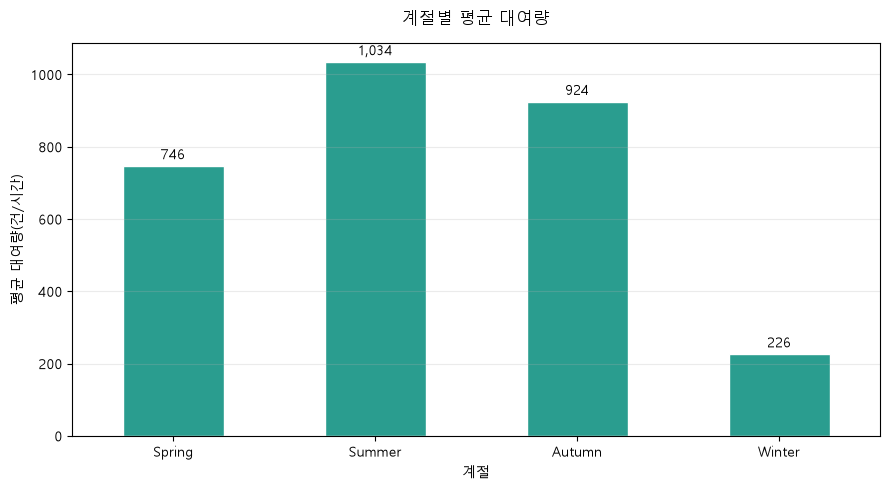

In [25]:
season_order = ["Spring", "Summer", "Autumn", "Winter"]
season_mean = operating.groupby("season")["rented_count"].mean().loc[season_order]

ax = season_mean.plot(kind="bar", color="#2A9D8F", edgecolor="white")
show_values(ax)
decorate(ax, "계절별 평균 대여량", "계절", "평균 대여량(건/시간)")
plt.show()

### 3.3 대여량 분포 히스토그램

`operating`의 시간당 대여량 분포를 히스토그램으로 그리고, 평균과 중앙값을 구하세요. 분포의 모양은 어떻습니까? 평균과 중앙값은 각각 히스토그램의 어느 구간에 있으며, 어느 쪽이 더 큽니까? 그 차이는 분포의 모양과 어떤 관계가 있습니까?

> **교수용 예시** 대여량이 작은 쪽에 많이 몰려 있고 오른쪽으로 길게 꼬리가 늘어진 분포입니다(가장 많이 몰린 구간은 약 120~239건). 평균(729.2건)이 중앙값(542건)보다 큽니다. 큰 값이 몇 개 있으면 평균이 위로 끌려 올라가기 때문입니다. 1.17에서 확인한 평균과 중앙값의 차이가 그래프에서는 꼬리의 길이로 보입니다.

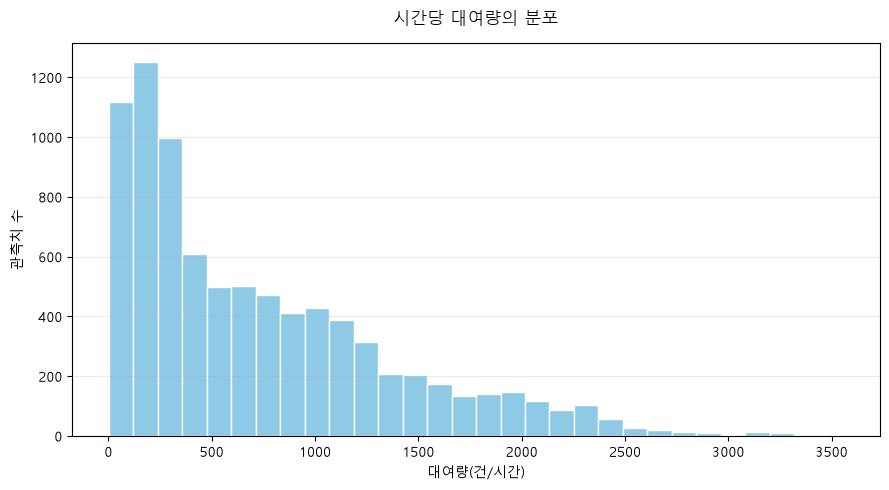

평균: 729.2
중앙값: 542.0


In [26]:
ax = operating["rented_count"].plot(kind="hist", bins=30, color="#8ECAE6", edgecolor="white")
decorate(ax, "시간당 대여량의 분포", "대여량(건/시간)", "관측치 수")
plt.show()

print("평균:", round(operating["rented_count"].mean(), 1))
print("중앙값:", operating["rented_count"].median())

### 3.4 계절별 대여량 상자그림

계절별 대여량 분포를 상자그림으로 비교하세요. 중앙값이 가장 높은 계절과 상자의 높이(IQR)가 가장 큰 계절은 어디입니까? (상자는 계절 이름의 알파벳 순서로 놓입니다.) 상자 위로 이어진 점들은 무엇이며, 1.16에서 확인한 이상값 후보와 같은 종류입니까? 이 점들을 **오류로 보고 삭제해도 되는지** 판단하세요.

**힌트** `boxplot(column="rented_count", by="season")`, 자동 제목은 `plt.suptitle("")`로 지웁니다.

> **교수용 예시** 중앙값은 여름(906건)이 가장 높고, IQR도 여름(916건)이 가장 큽니다. 겨울은 중앙값 203건, IQR 195건으로 상자가 낮고 좁습니다. 상자 위의 점은 각 계절의 Q3 + 1.5 × IQR을 넘는 값(이상값 후보)이며 봄 21건, 여름 25건, 가을 19건, 겨울 59건입니다. 1.16와 같은 종류이고, 대여가 몰린 시간대의 실제 수요이므로 오류로 보고 삭제하지 않습니다. 계절을 나누어 기준을 세우면 전체 기준일 때와 후보의 수가 달라진다는 점도 확인할 수 있습니다.

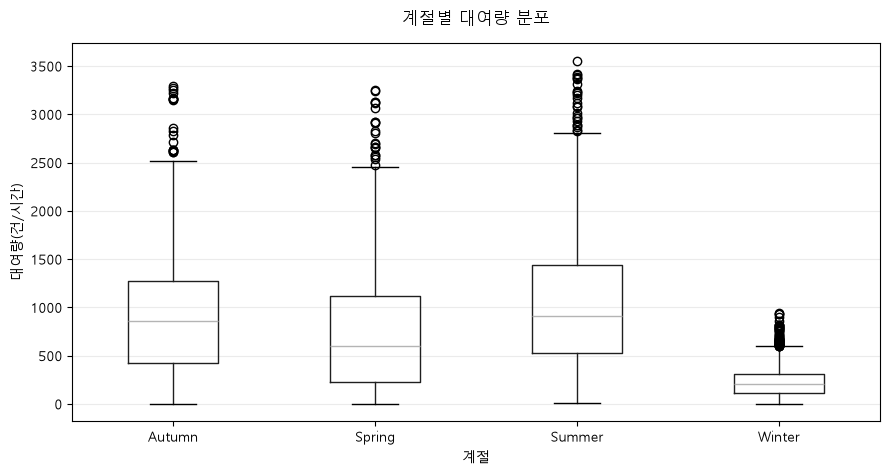

In [27]:
ax = operating.boxplot(column="rented_count", by="season", grid=False, figsize=(9, 5))
plt.suptitle("")
decorate(ax, "계절별 대여량 분포", "계절", "대여량(건/시간)")
plt.show()

### 3.5 공휴일 여부별 시간대 평균 대여량 선그래프

공휴일과 공휴일이 아닌 때를 두 개의 선으로 나누어, 시간대(0~23시)별 평균 대여량을 선그래프로 그리세요. 범례와 제목, 축 이름을 붙이세요. 두 선의 **최고점 시간대**는 언제입니까? 공휴일이 아닌 때에만 나타나는 모양이 있습니까? 이 그래프를 해석할 때 **공휴일 기록의 수**를 어떻게 고려해야 합니까?

**힌트** `groupby(["hour", "holiday"])` → `mean()` → `unstack()` → `plot(kind="line")`

> **교수용 예시** 공휴일이 아닌 때는 18시(1,590건)가 최고점이고 8시(1,085건)에도 뚜렷한 봉우리가 있어 출근과 퇴근 시간대의 두 봉우리 모양입니다. 공휴일은 17시(879건)가 최고점이고 8시(369건)의 봉우리는 거의 없습니다. 다만 공휴일 기록은 408건(24시간씩 약 17일치)뿐이고 겨울에 몰려 있으므로(2.3), 공휴일 선의 세부 모양은 조심해서 읽어야 합니다.

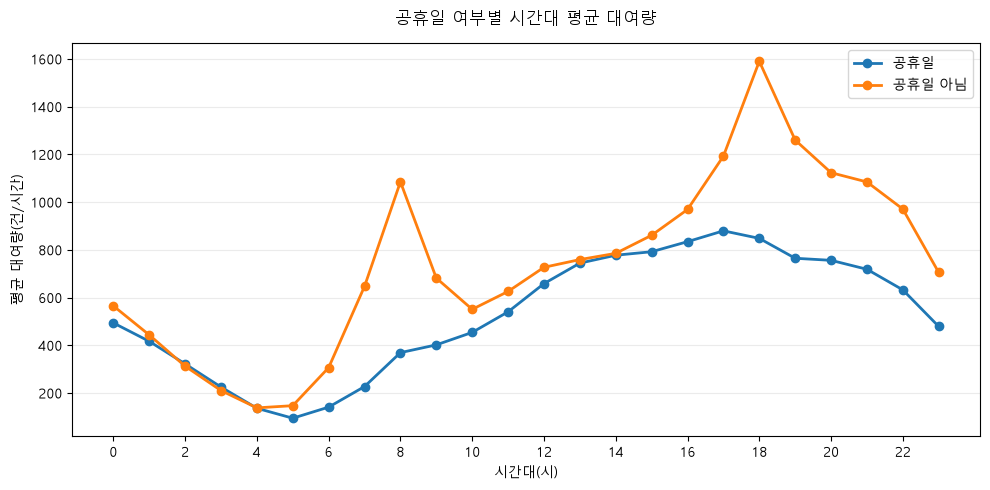

In [28]:
hour_holiday = operating.groupby(["hour", "holiday"])["rented_count"].mean().unstack()

ax = hour_holiday.plot(kind="line", marker="o", linewidth=2, figsize=(10, 5))
ax.set_xticks(range(0, 24, 2))
ax.legend(["공휴일", "공휴일 아님"])
decorate(ax, "공휴일 여부별 시간대 평균 대여량", "시간대(시)", "평균 대여량(건/시간)")
plt.show()

### 3.6 기온과 대여량의 산점도

기온(`temperature`)과 대여량의 관계를 산점도로 그리세요. 점이 많이 겹치므로 점을 작고 투명하게 그리세요. 상관계수도 구하세요. 기온이 높을수록 대여량이 어떻게 달라집니까? 같은 기온에서도 대여량이 크게 퍼져 있는 이유가 될 만한 **다른 변수**를 하나 쓰고, 상관계수만으로 "기온 때문에 늘어난다"고 말할 수 없는 이유를 쓰세요.

**힌트** `plot(kind="scatter", x=…, y=…, s=…, alpha=…)`, `corr()`

> **교수용 예시** 기온이 높을수록 대여량이 대체로 늘어나는 오른쪽 위 방향의 흐름이 보이고, 상관계수는 0.56입니다. 같은 기온에서도 대여량이 0에 가까운 값부터 매우 큰 값까지 퍼져 있는데, 시간대(출퇴근 여부)나 비·눈이 오는지가 이유가 될 수 있습니다. 상관계수는 함께 움직이는 정도만 보여 주고, 여름에 기온도 높고 이용도 많은 것처럼 **제3의 변수**가 두 값에 함께 영향을 줄 수 있으므로 원인을 단정할 수 없습니다.

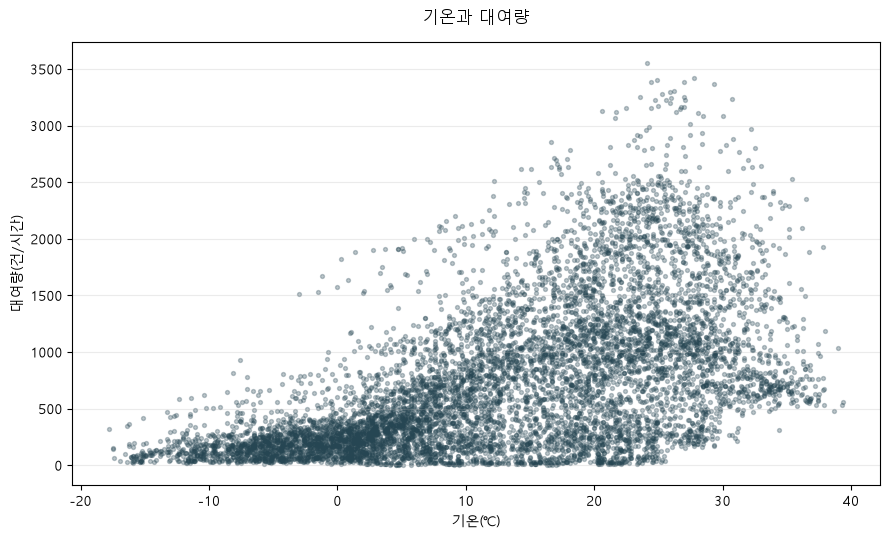

np.float64(0.56)

In [29]:
ax = operating.plot(kind="scatter", x="temperature", y="rented_count", s=8, alpha=0.3, color="#264653", figsize=(9, 5.5))
decorate(ax, "기온과 대여량", "기온(℃)", "대여량(건/시간)")
plt.show()

operating["temperature"].corr(operating["rented_count"]).round(2)

### 3.7 계절과 강수 여부별 묶은 막대그래프

1.10에서 만든 `is_rain` 열로 비 오는 시간과 비 안 오는 시간의 평균 대여량을 **계절을 같게 놓고** 비교하려고 합니다. 계절별로 두 평균이 막대 두 개로 나란히 놓이는 묶은 막대그래프를 그리세요. 모든 계절에서 비 오는 쪽이 낮습니까? 그래프에는 나타나지 않지만 해석할 때 반드시 함께 읽어야 하는 정보는 무엇입니까?

**힌트** `groupby(["season", "is_rain"])` → `mean()` → `unstack()` → `plot(kind="bar")`

> **교수용 예시** 모든 계절에서 비 오는 쪽 막대가 낮습니다. 예를 들어 여름은 비 안 옴 1,110건에서 비 옴 258건으로 줄어듭니다. 그래프에는 각 막대가 **몇 건의 평균인지**가 나타나지 않습니다. 비 오는 시간은 계절마다 건수가 다르고 적은 계절도 있으므로, 건수가 적은 막대는 우연히 달라질 수 있다는 점을 `count`로 따로 확인해 함께 읽어야 합니다.

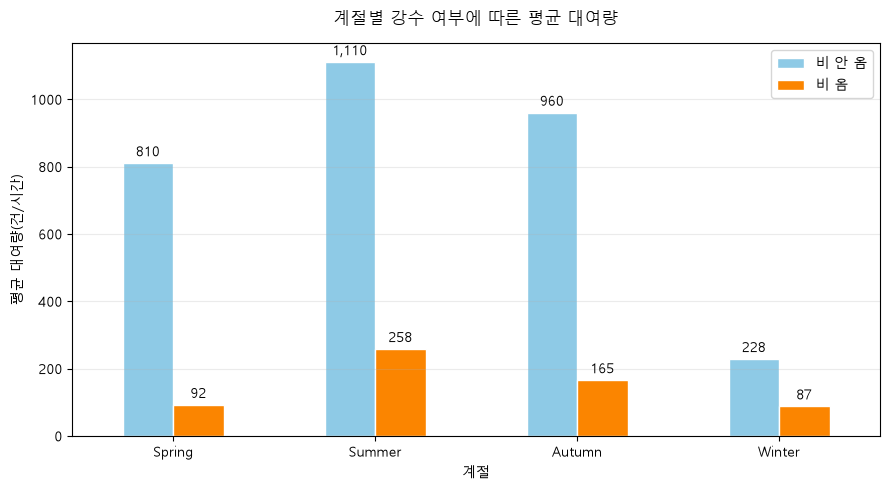

In [30]:
rain_season = (
    operating
    .groupby(["season", "is_rain"])["rented_count"]
    .mean()
    .unstack()
    .loc[["Spring", "Summer", "Autumn", "Winter"]]
)
rain_season.columns = ["비 안 옴", "비 옴"]

ax = rain_season.plot(kind="bar", color=["#8ECAE6", "#FB8500"], edgecolor="white")
show_values(ax)
decorate(ax, "계절별 강수 여부에 따른 평균 대여량", "계절", "평균 대여량(건/시간)")
plt.show()

### 3.8 축의 시작점 점검

3.2의 계절별 평균 막대그래프를 **y축이 `700`에서 시작하도록** 바꿔 다시 그리세요. 봄과 가을의 차이가 0에서 시작할 때와 비교해 어떻게 다르게 보입니까? 막대그래프의 y축은 어디에서 시작해야 하며 이유는 무엇입니까? 같은 규칙이 선그래프(3.5)에도 적용됩니까?

**힌트** `set_ylim(700, 1100)`

> **교수용 예시** 실제 평균은 봄 746건, 가을 924건으로 가을이 약 1.24배입니다. y축을 700에서 시작하면 봄 막대는 46만큼, 가을 막대는 224만큼만 보여서 가을이 봄의 몇 배처럼 보이고, 겨울(226건)은 축 범위 밖이라 막대가 아예 보이지 않습니다. 막대그래프는 **막대의 길이가 값의 크기**를 뜻하므로 y축은 0에서 시작해야 합니다. 선그래프는 크기가 아니라 **변화의 방향과 모양**을 보므로 축을 0에서 시작하지 않아도 되지만, 축 범위를 눈금에 분명히 밝혀야 합니다.

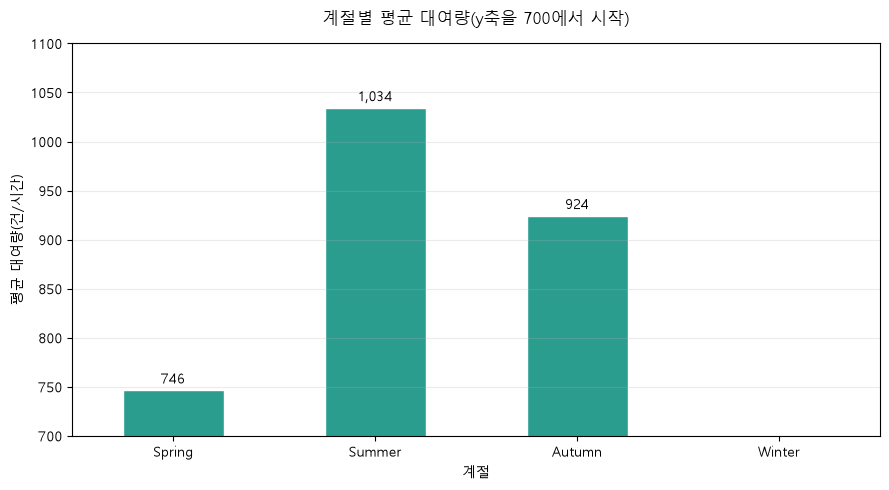

In [31]:
ax = season_mean.plot(kind="bar", color="#2A9D8F", edgecolor="white")
ax.set_ylim(700, 1100)
show_values(ax)
decorate(ax, "계절별 평균 대여량(y축을 700에서 시작)", "계절", "평균 대여량(건/시간)")
plt.show()

### 3.9 그래프를 문장으로 해석하기

3.2~3.7의 그래프 중 하나를 골라, 다음 세 부분으로 나누어 쓰세요.

1. **확인한 사실** 그래프에서 읽은 내용을 숫자와 함께 씁니다.
2. **가능한 해석** 왜 그럴 수 있는지 씁니다. 원인을 단정하지 않습니다.
3. **한계** 이 그래프로는 알 수 없는 것을 씁니다. 표본이 작은 그룹이나 통제하지 못한 조건을 포함합니다.

> **교수용 예시 (3.5 선그래프)**
> - **확인한 사실** 공휴일이 아닌 때는 8시와 18시에 두 봉우리가 있고, 공휴일은 17시에 하나의 완만한 봉우리가 있습니다.
> - **가능한 해석** 평일에는 출퇴근 이동이, 공휴일에는 낮 시간의 여가 이용이 반영된 모양일 수 있습니다.
> - **한계** 이용 목적은 기록되어 있지 않아 이유를 확인할 수 없습니다. 공휴일 기록이 적고 겨울에 몰려 있어 날씨와 계절의 영향이 섞여 있습니다. 공휴일이 아닌 때에는 주말도 포함되어 있어 평일만의 모양이 아닙니다.

### 3.10 분석 질문에 답하는 보고용 그래프

처음 질문으로 돌아갑니다. "서울 공공자전거의 시간대별 평균 대여량은 어떻게 다르며, 어느 시간대에 대여가 가장 많은가?" 이 질문에 답하는 **보고용 그래프 한 장**을 만드세요.

- 그래프 종류를 고르고 이유를 쓰세요.
- 제목과 축 이름을 붙이세요.
- 가장 많은 시간대와 그 평균을 **코드로** 구하세요.
- 그래프 아래에 **결론을 한 문장**으로 쓰세요. 전처리 기준(1.15)과 자료의 범위(서울 전체 합계, 1년)도 밝히세요.

> **교수용 예시** 선그래프를 고릅니다. 시간 순서에 따른 변화를 보는 질문이기 때문입니다.
> **결론** 비운영 시간을 제외한 8,465개 관측치로 보면, 시간당 평균 대여량은 새벽 4시 137.5건에서 18시 1,554건까지 약 11.3배 차이가 나며 18시가 가장 많습니다. 이 결과는 서울 전체의 1년 합계 자료이므로 특정 대여소의 상황을 말해 주지는 않습니다.

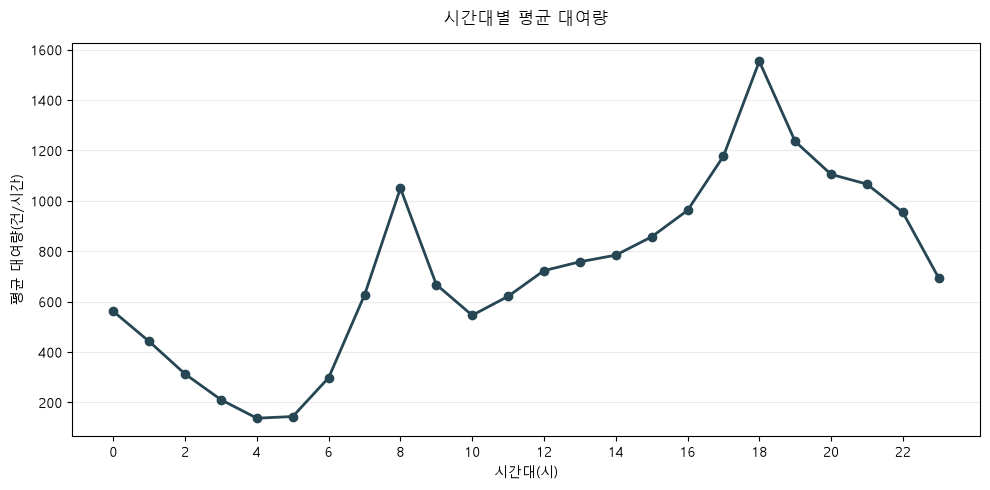

가장 많은 시간대: 18시 (평균 1,554건)


In [32]:
hourly_mean = operating.groupby("hour")["rented_count"].mean()
peak_hour = hourly_mean.idxmax()
peak_value = hourly_mean.max()

ax = hourly_mean.plot(kind="line", marker="o", linewidth=2, color="#264653", figsize=(10, 5))
ax.set_xticks(range(0, 24, 2))
decorate(ax, "시간대별 평균 대여량", "시간대(시)", "평균 대여량(건/시간)")
plt.show()

print(f"가장 많은 시간대: {peak_hour}시 (평균 {peak_value:,.0f}건)")

### 교수용 지도 포인트 (3번)

- **3.4** 상자그림의 점을 오류로 보고 지우지 않게 하는 것이 핵심입니다. 이론의 카페 45분(오류 가능)과 대비시킵니다.
- **3.6** 상관계수가 높아도 원인을 말하지 않는 습관을 확인합니다.
- **3.8** 같은 데이터가 y축 시작점에 따라 다르게 보이는 것을 직접 그려서 확인하게 합니다.
- **3.10** 그래프에는 반드시 결론 문장과 범위·전처리 기준이 따라붙어야 합니다.